# Simple model: logistic regression on simple image features

**Pipeline:** image → simple feature vector → standardize → one linear layer → softmax → Small / Medium / Large

No hidden layers, no CNN, no HOG/LBP. This is the baseline the other models are compared against.

The notebook does two things:
1. **Tuning (section 6):** tries several simple features and settings, and picks one using the validation set only.
2. **Final model (section 7–8):** the chosen setup, scored on the test set.

What we ended up choosing, and why:

| Decision | Choice | Why |
|---|---|---|
| Feature | `combo` = brightness histogram + ink density + color (76 numbers) | Best val macro-F1, smallest train–val gap, not sensitive to C |
| Class weighting | none | The augmented training set is already close to balanced |
| Training rows | all (original + rescan + augmented) | Without class weighting, training on originals only collapses to always predicting Large |

Sections: 1 settings · 2 data · 3 features · 4 look at the features · 5 chance level · 6 compare features (val) · 7 compare training rows (val) · 8 final model · 9 test · 10 save

## 1. Settings and imports

Ignored the warnings for Pillow's size limit and sklearn's convergence warning. 

For the feature settings, I set thumbnail sizes, the number of hist bins, the ink grid size, and the list of C values to test. 

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage.filters import threshold_otsu

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None # A few fold-out maps are huge, so turn off the size guard

warnings.filterwarnings("ignore") # Some of the bigger C values don't fully converge

In [2]:
# ---- Paths ----
# The repo root is the first folder that has a .git folder in it.
ROOT = None
for folder in [Path.cwd()] + list(Path.cwd().parents): #src: https://stackoverflow.com/questions/973473/getting-a-list-of-all-subdirectories-in-the-current-directory
    if (folder / ".git").exists():
        ROOT = folder
        break

PROC = ROOT / "data" / "processed"   # images + manifest.csv from preprocessing
RESULTS_DIR = ROOT / "data" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ---- Feature settings ----
# Thumbnail sizes as (width, height). Processed images are 672 x 1024, so these keep the shape.
THUMB_SIZES = [(32, 48)] #can add more if we want to test

HIST_BINS = 32

INK_GRID_ROWS = 6  # ink density is measured in a 6 x 4 grid of cells
INK_GRID_COLS = 4

COLOR_BINS = 16

COLOR_THUMB_SIZE = (168, 256) # color doesn't need full resolution

# Contrast stretch: these percentiles of each image become 0 (ink) and 1 (paper)
STRETCH_LOW = 1
STRETCH_HIGH = 99


# ---- Model settings ----
# C = how much we let the model fit the training data. Small C = simpler model.
C_GRID = np.logspace(-6, 2, 13) # 13 values from 0.000001 to 100
MAX_ITER = 3000
SEED = 281

CLASS_NAMES = ["Small", "Medium", "Large"]  # labels 0, 1, 2

## 2. Load the data

Labels and splits come from manifest.csv (see the README). The train split has three kinds of rows:
- original: the kept scan of each map
- rescan: another library's scan of the same map
- augmented: a synthetic copy (flipped, slightly tilted, etc.)

Val and test have exactly one scan per map.

I read manifest.csv, split into train/val/test, then pull out the labels and count how many of each I have. I also wanted to double check there is no leakage between the sets. 

In [3]:
# Read manifest.csv and split into train/val/test
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)

splits = {}
for split_name in ["train", "val", "test"]:
    rows = manifest[manifest["split"] == split_name]
    splits[split_name] = rows.reset_index(drop=True)

# the labels for each split, as numpy arrays
y = {}
for split_name in splits:
    y[split_name] = splits[split_name]["label"].to_numpy()

for split_name in splits:
    counts = np.bincount(y[split_name], minlength=3)
    print(split_name, "->  Small:", counts[0], "  Medium:", counts[1], "  Large:", counts[2], "  total:", counts.sum())

train ->  Small: 590   Medium: 1240   Large: 1240   total: 3070
val ->  Small: 26   Medium: 54   Large: 213   total: 293
test ->  Small: 25   Medium: 53   Large: 213   total: 291


In [4]:
# Leakage check. The same map (source_id) or split group (group_id) can't show up in two different splits.
for column in ["source_id", "group_id"]:
    train_ids = set(splits["train"][column])
    val_ids = set(splits["val"][column])
    test_ids = set(splits["test"][column])

    overlap = len(train_ids & val_ids) + len(train_ids & test_ids) + len(val_ids & test_ids)
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

source_id shared between splits: 0
group_id shared between splits: 0


## 3. Features

All of these are simple features that summarize brightness and color. They don't look for edges, shapes or texture.

**Contrast stretch:** Scans differ a lot in paper color (white vs. yellowed) and brightness. Stretching each image so its darkest 1% → 0 and brightest 1% → 1 to standardize.

**Ink:** Otsu's method picks a brightness threshold for each image that best separates dark pixels (ink) from light ones (paper). Source: https://en.wikipedia.org/wiki/Otsu%27s_method 

**Color:** Saturation = how colorful a pixel is. Old paper is a bit yellow, so I subtracted the paper's own saturation (the median, since I think most of the page is paper) and only keep color beyond that.

| Feature | What it is | 
|---|---|
| pixels_32 | Same, but contrast-stretched first, size 32 × 48 |
| hist_norm | Same, but contrast-stretched first |
| ink | Fraction of ink pixels, overall + in each cell of a 6 × 4 grid |
| color | Saturation beyond the paper's own tint: 16-bin histogram + 3 summary numbers |
| combo | hist_norm + ink + color side by side |

#### Helper Functions ####
- load_rgb: opens a file
- to_gray: converts to grayscale (0-1)
- contrast_stretch: makes each image's darkest 1% black and brightest 1% white (to make yellowed and white paper look alike)
- shrink: makes a thumbnail by averaging blocks of pixels
- fraction_histogram: counts what share of values is in each brightness range

In [5]:
def load_rgb(path):
    # open an image and return an array of shape (height, width, 3) with values 0-255
    with Image.open(path) as img:
        rgb = np.asarray(img.convert("RGB")) #src : https://www.pluralsight.com/resources/blog/guides/importing-image-data-into-numpy-arrays
    return rgb


def to_gray(rgb):
    # grayscale, from 0.0 (black) to 1.0 (white)
    gray_img = Image.fromarray(rgb).convert("L") #src: https://stackoverflow.com/questions/12201577/how-can-i-convert-an-rgb-image-into-grayscale-in-python
    return np.asarray(gray_img, dtype=np.float32) / 255.0


def contrast_stretch(gray):
    low = np.percentile(gray, STRETCH_LOW) #src: https://stackoverflow.com/questions/2374640/how-do-i-calculate-percentiles-with-python-numpy
    high = np.percentile(gray, STRETCH_HIGH)

    # a blank image has nothing to stretch, so leave it alone
    if high - low < 0.000001:
        return gray

    stretched = (gray - low) / (high - low) #src: https://stackoverflow.com/questions/42257173/contrast-stretching-in-python-opencv 
    stretched = np.clip(stretched, 0.0, 1.0)
    return stretched


def shrink(gray, size):
    # Shrink to size = (width, height). Image.BOX averages all the pixels that land in each new pixel, so thin lines still count a little instead of vanishing.
    img = Image.fromarray(gray.astype(np.float32), mode="F") 
    small = img.resize(size, Image.BOX) #using BOX since I want the average for every pixel in the block
    return np.asarray(small, dtype=np.float32)


def fraction_histogram(values, n_bins):
    # fraction of values in each of n_bins equal-width bins between 0 and 1 (adds up to 1)
    counts, edges = np.histogram(values, bins=n_bins, range=(0.0, 1.0))
    return counts / counts.sum()

#### Feature Functions ####
 - ink_density: After contrast-stretching, I use Otsu's method to choose a threshold for dark/light for each image. This way we can differentiate between ink and paper. Instead of giving the model every pixel (which could lead to overfitting by memorizing the specific patterns), I divide the map into 24 big boxes (6 rows x 4 cols) and write what fraction of the pixels in each box are ink. I also report the overall percentage across the whole map of ink. 
 - color_features: Measure how colorful pixels are (beyond the paper's color)

In [6]:
def ink_mask(stretched):
    # True wherever the pixel is ink
    threshold = threshold_otsu(stretched)
    return stretched < threshold


def ink_density(stretched):
    mask = ink_mask(stretched)

    values = [mask.mean()]   # overall ink fraction first

    # split the rows and the columns into nearly-equal chunks to make the grid
    row_chunks = np.array_split(np.arange(mask.shape[0]), INK_GRID_ROWS)
    col_chunks = np.array_split(np.arange(mask.shape[1]), INK_GRID_COLS)

    for rows in row_chunks:
        for cols in col_chunks:
            cell = mask[rows[0] : rows[-1] + 1, cols[0] : cols[-1] + 1]
            values.append(cell.mean())

    return np.array(values)   # 1 + 24 = 25 numbers


def extra_saturation(rgb):
    small = Image.fromarray(rgb).resize(COLOR_THUMB_SIZE, Image.BOX)
    hsv = np.asarray(small.convert("HSV"), dtype=np.float32) / 255.0
    saturation = hsv[:, :, 1]

    paper_saturation = np.median(saturation)
    extra = np.clip(saturation - paper_saturation, 0.0, 1.0)
    return extra, saturation, paper_saturation


def color_features(rgb):
    extra, saturation, paper_saturation = extra_saturation(rgb)

    values = list(fraction_histogram(extra, COLOR_BINS))
    values.append(saturation.mean())
    values.append(paper_saturation)
    # fraction of pixels that are clearly colored
    values.append((extra > 0.15).mean())

    return np.array(values)   # 16 + 3 = 19 numbers

#### Computing One Feature ####

one_feature(rgb, name) takes one loaded image and the name of a feature, and returns that feature as a 1-D array of numbers.

- Every feature starts from the grayscale image
- pixels_raw, hist_raw and color use the image as scanned
- The others use the contrast-stretched image (darkest 1% → black, brightest 1% → white), so differences in paper color and scanner brightness don't drown out the map itself
- combo joins hist_norm, ink and color into one 76-number vector


In [7]:
# Compute one feature for one image, by name.
def one_feature(rgb, name):
    gray = to_gray(rgb)

    if name == "pixels_raw":
        return shrink(gray, (32, 48)).ravel()
    if name == "hist_raw":
        return fraction_histogram(gray, HIST_BINS)
    if name == "color":
        return color_features(rgb)

    # everything below uses the contrast-stretched image
    stretched = contrast_stretch(gray)

    if name == "pixels_32":
        return shrink(stretched, (32, 48)).ravel()
    if name == "hist_norm":
        return fraction_histogram(stretched, HIST_BINS)
    if name == "ink":
        return ink_density(stretched)
    if name == "combo":
        part1 = fraction_histogram(stretched, HIST_BINS)
        part2 = ink_density(stretched)
        part3 = color_features(rgb)
        return np.concatenate([part1, part2, part3])


BASE_FEATURES = ["pixels_32", "hist_norm", "ink", "color"]
ALL_FEATURES = BASE_FEATURES + ["combo"]

#### Computing Features for Every Image ####

For each split (train, val, test), we go through every image:
1. Open the image once.
2. Compute all nine features from that one loaded image.
3. Add each feature's numbers to that feature's list.

At the end of each split, each list becomes a 2-D array: one row per image, one column per number in the feature.
The result is stored as X[feature name][split name], e.g. X["ink"]["train"].

In [8]:
# Compute every feature for every image. Takes several minutes.
X = {}
for name in ALL_FEATURES:
    X[name] = {}

for split_name in ["train", "val", "test"]:
    # start with an empty list for each feature
    rows = {}
    for name in ALL_FEATURES:
        rows[name] = []

    for path in splits[split_name]["path"]:
        rgb = load_rgb(PROC / path)
        for name in ALL_FEATURES:
            rows[name].append(one_feature(rgb, name))

    # turn each list of rows into a 2D array
    for name in ALL_FEATURES:
        X[name][split_name] = np.array(rows[name])
    print(split_name, "done")

train done
val done
test done


#### Timing Each Feature (for the Efficiency Section) ####

To compare costs fairly, we time each feature on the same 50 training images:
1. Load the 50 images once and time how long loading takes.
2. For each feature, time how long it takes to compute on all 50 already-loaded images.
3. Divide by 50 to get the average time per image.

Total cost per image = loading time + that feature's computing time. This is the number used in the efficiency-vs-accuracy comparison.

In [9]:
# How long does each feature take per image? Time it on 50 training images.
sample_paths = list(splits["train"]["path"][:50])

sec_per_image = {}
for name in ALL_FEATURES:
    start = time.perf_counter()
    for path in sample_paths:
        rgb = load_rgb(PROC / path)
        one_feature(rgb, name)
    sec_per_image[name] = (time.perf_counter() - start) / len(sample_paths)

for name in ALL_FEATURES:
    print(name, "-", X[name]["train"].shape[1], "numbers,", round(sec_per_image[name] * 1000, 1), "ms per image")

pixels_32 - 1536 numbers, 13.6 ms per image
hist_norm - 32 numbers, 18.5 ms per image
ink - 25 numbers, 18.6 ms per image
color - 19 numbers, 9.0 ms per image
combo - 76 numbers, 27.4 ms per image


## 4. Look at the features

One training map per class, shown four ways. Then class averages, using only one row per map (variant == "original") so augmented copies don't count twice. Not using the augmentations is only for this visualization! I use the augmented copies in the actual model. 

If the classes look the same here, a linear model won't be able to tell them apart either.

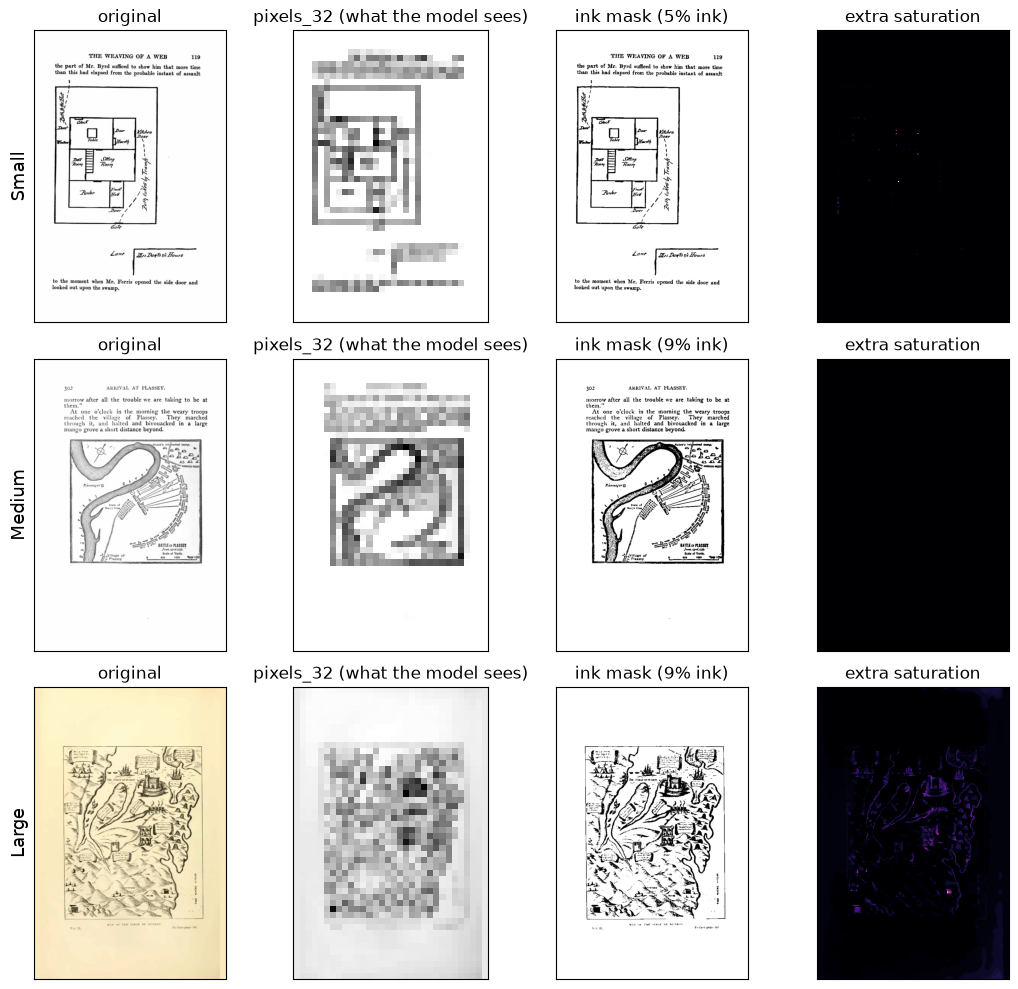

In [10]:
rng = np.random.default_rng(SEED)
train_rows = splits["train"]
is_original = (train_rows["variant"] == "original").to_numpy()

# want an image with 3 rows (1 per class) and 4 cols (1 per feature: original, pixels_32, ink mask, and extra saturation)
fig, axes = plt.subplots(3, 4, figsize=(11, 10))

for class_id in range(3):
    # pick a random original map from this class
    candidates = np.where(is_original & (y["train"] == class_id))[0]
    i = rng.choice(candidates)

    rgb = load_rgb(PROC / train_rows.loc[i, "path"])
    stretched = contrast_stretch(to_gray(rgb))
    mask = ink_mask(stretched)
    extra, saturation, paper_saturation = extra_saturation(rgb)

    axes[class_id, 0].imshow(rgb)
    axes[class_id, 0].set_title("original")

    axes[class_id, 1].imshow(shrink(stretched, (32, 48)), cmap="gray")
    axes[class_id, 1].set_title("pixels_32 (what the model sees)")

    axes[class_id, 2].imshow(mask, cmap="gray_r")
    axes[class_id, 2].set_title(f"ink mask ({mask.mean():.0%} ink)")

    axes[class_id, 3].imshow(extra, cmap="magma", vmin=0, vmax=0.5)
    axes[class_id, 3].set_title("extra saturation")

    for ax in axes[class_id]:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[class_id, 0].set_ylabel(CLASS_NAMES[class_id], fontsize=13)

plt.tight_layout()
plt.show()

#### Look at Class Averages ####

Instead of showing one example, I'm averaging a feature over all the maps in a class. 

For example, it averages the ink fraction of every Small map, then of every Medium map, then of every Large map. If the three classes’ averages look about the same, the feature probably can’t tell them apart.



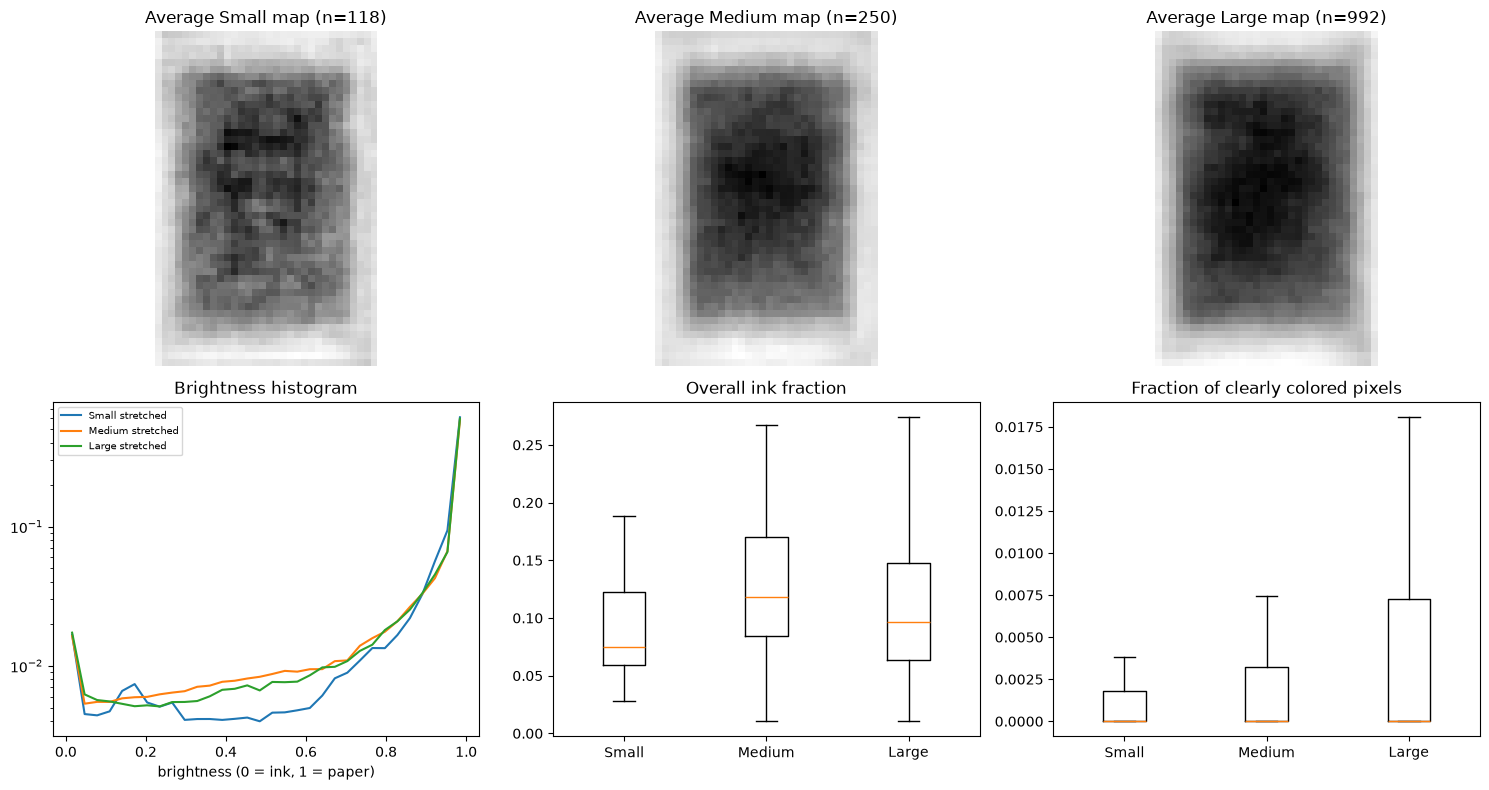

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# --- top row: the average 32 x 48 thumbnail of each class ---
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    mean_thumb = X["pixels_32"]["train"][rows].mean(axis=0)

    axes[0, class_id].imshow(mean_thumb.reshape(48, 32), cmap="gray")
    axes[0, class_id].set_title(f"Average {CLASS_NAMES[class_id]} map (n={rows.sum()})")
    axes[0, class_id].axis("off")


# --- bottom left: brightness histogram before and after the stretch ---
bin_centers = (np.arange(HIST_BINS) + 0.5) / HIST_BINS
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    norm = X["hist_norm"]["train"][rows].mean(axis=0)
    axes[1, 0].plot(bin_centers, norm, label=CLASS_NAMES[class_id] + " stretched")

axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("brightness (0 = ink, 1 = paper)")
axes[1, 0].set_title("Brightness histogram")
axes[1, 0].legend(fontsize=7)


# --- bottom middle: overall ink fraction (column 0 of the ink feature) ---
groups = []
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    groups.append(X["ink"]["train"][rows, 0])
axes[1, 1].boxplot(groups, showfliers=False)
axes[1, 1].set_xticks([1, 2, 3], CLASS_NAMES)
axes[1, 1].set_title("Overall ink fraction")


# --- bottom right: fraction of clearly colored pixels (last column of color) ---
groups = []
for class_id in range(3):
    rows = is_original & (y["train"] == class_id)
    groups.append(X["color"]["train"][rows, -1])
axes[1, 2].boxplot(groups, showfliers=False)
axes[1, 2].set_xticks([1, 2, 3], CLASS_NAMES)
axes[1, 2].set_title("Fraction of clearly colored pixels")

plt.tight_layout()
plt.show()

## 5. Chance level

Two dummy "classifiers": 
- most_frequent: always predicts the most common class (Large)
- stratified: guesses at random in the same proportion as the training classes (~20% for Small, ~40% Medium, ~40% Large)
I'm using sklearn's DummyClassifier: https://scikit-learn.org/0.18/modules/generated/sklearn.dummy.DummyClassifier.html

I'm judging models using the macro-F1: the F1 score of each class, averaged with equal weight. 

Plain accuracy is misleading here because ~73% of val/test maps are Large, so always guessing Large already gets ~73% accuracy.

In [12]:
# Helper function to get the accuracy, balanced accuract, and macro-f1
def get_scores(y_true, y_pred):
    scores = {}
    scores["accuracy"] = accuracy_score(y_true, y_pred)
    scores["balanced_acc"] = balanced_accuracy_score(y_true, y_pred)# average recall per class
    scores["macro_f1"] = f1_score(y_true, y_pred, average="macro")
    return scores


dummy_rows = []
for strategy in ["most_frequent", "stratified"]: #src: https://scikit-learn.org/0.18/modules/generated/sklearn.dummy.DummyClassifier.html, https://github.com/DavidMertz/ML-Webinar/blob/main/Classification.ipynb 
    dummy = DummyClassifier(strategy=strategy, random_state=SEED)
    dummy.fit(X["combo"]["train"], y["train"])

    for split_name in ["val", "test"]:
        predictions = dummy.predict(X["combo"][split_name])
        row = {"model": "dummy_" + strategy, "split": split_name}
        row.update(get_scores(y[split_name], predictions))
        dummy_rows.append(row)

dummy_table = pd.DataFrame(dummy_rows)

val_dummies = dummy_table[dummy_table["split"] == "val"]
test_dummies = dummy_table[dummy_table["split"] == "test"]
chance_val_f1 = val_dummies["macro_f1"].max()
chance_test_f1 = test_dummies["macro_f1"].max()

dummy_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1
0,dummy_most_frequent,val,0.184,0.333,0.104
1,dummy_most_frequent,test,0.182,0.333,0.103
2,dummy_stratified,val,0.352,0.271,0.256
3,dummy_stratified,test,0.354,0.270,0.255


From the table above, we can see that the Macro F1 score to beat is ~0.26 (accuracy ~0.35)

## 6. Tuning: compare features (validation set only)

Model: Multinomial logistic regression has one weight per feature (plus a bias) for each class. It scores an image as weights · features + bias, and turns the three scores into probabilities with softmax.

C: controls how strongly large weights are penalized. Small C = higher penalty -> simpler model (may underfit). Large C = weaker penalty (may overfit). Source: https://www.kaggle.com/code/usman8/logistic-regression-tuning-the-c-parameter

For each feature, we try every C in C_GRID. Each time: fit on train, score on val. The test set isn't used in this section.

Choosing C (one-standard-error rule): We will pick the C with the highest validation score.

This section fits about 250 models; it can take several minutes, mostly for the big pixel features at large C.

In [13]:
def fit_and_score(X_train, y_train, X_val, y_val, C, class_weight):
    # Scale: every feature gets mean 0 and std 1, using the training data only.
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
    model.fit(X_train_scaled, y_train)

    train_f1 = f1_score(y_train, model.predict(X_train_scaled), average="macro")
    val_pred = model.predict(X_val_scaled)
    return train_f1, val_pred

def pick_C(results):
    # Pick the C with the highest validation macro-F1
    best = results[0]
    for r in results:
        if r["val_macro_f1"] > best["val_macro_f1"]:
            best = r
    return best

In [15]:
#### Searching C for One Setting per Feature, Plus Combo ####

# One setting per feature type: the class_weight that did best in our full search.
SETTINGS = [
    {"feature": "pixels_32"},
    {"feature": "hist_norm"},
    {"feature": "ink"},
    {"feature": "color"},
    {"feature": "combo"},
]

all_rows = []      # every C tried, for the curve plots
summary_rows = []  # one row per setting, at its chosen C

for setting in SETTINGS:
    name = setting["feature"]
    class_weight = None

    # Try every C
    results = []
    for C in C_GRID:
        train_f1, val_pred = fit_and_score(X[name]["train"], y["train"],
                                           X[name]["val"], y["val"], C, class_weight)
        val_f1 = f1_score(y["val"], val_pred, average="macro")
        results.append({"C": C, "train_macro_f1": train_f1, "val_macro_f1": val_f1, "val_pred": val_pred})

    chosen = pick_C(results)

    for r in results:
        all_rows.append({"feature": name, "C": r["C"],
                         "train_macro_f1": r["train_macro_f1"], "val_macro_f1": r["val_macro_f1"]})

    summary_rows.append({"feature": name, "chosen_C": chosen["C"],
                         "val_macro_f1": chosen["val_macro_f1"], 
                         "train_macro_f1": chosen["train_macro_f1"],
                         "n_features": X[name]["train"].shape[1],
                         "ms_per_image": sec_per_image[name] * 1000})

    print(name,  "| val macro-F1 =", round(chosen["val_macro_f1"], 3))

curves = pd.DataFrame(all_rows)
feature_table = pd.DataFrame(summary_rows)

pixels_32 | val macro-F1 = 0.371
hist_norm | val macro-F1 = 0.372
ink | val macro-F1 = 0.389
color | val macro-F1 = 0.219
combo | val macro-F1 = 0.4


In [16]:
# Compare to the chance model F1
feature_table["beats_chance_by"] = feature_table["val_macro_f1"] - chance_val_f1
feature_table = feature_table.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)

print(f"Chance level on val: {chance_val_f1:.3f}")
feature_table.round(4)

Chance level on val: 0.256


,feature,chosen_C,val_macro_f1,train_macro_f1,n_features,ms_per_image,beats_chance_by
0,combo,0.2154,0.3998,0.4844,76,27.4249,0.1437
1,ink,0.0464,0.3885,0.3892,25,18.5820,0.1324
2,hist_norm,0.0100,0.3722,0.4052,32,18.5480,0.1161
3,pixels_32,0.0000,0.3711,0.3812,1536,13.5981,0.1150
4,color,0.0000,0.2189,0.2860,19,8.9510,-0.0372


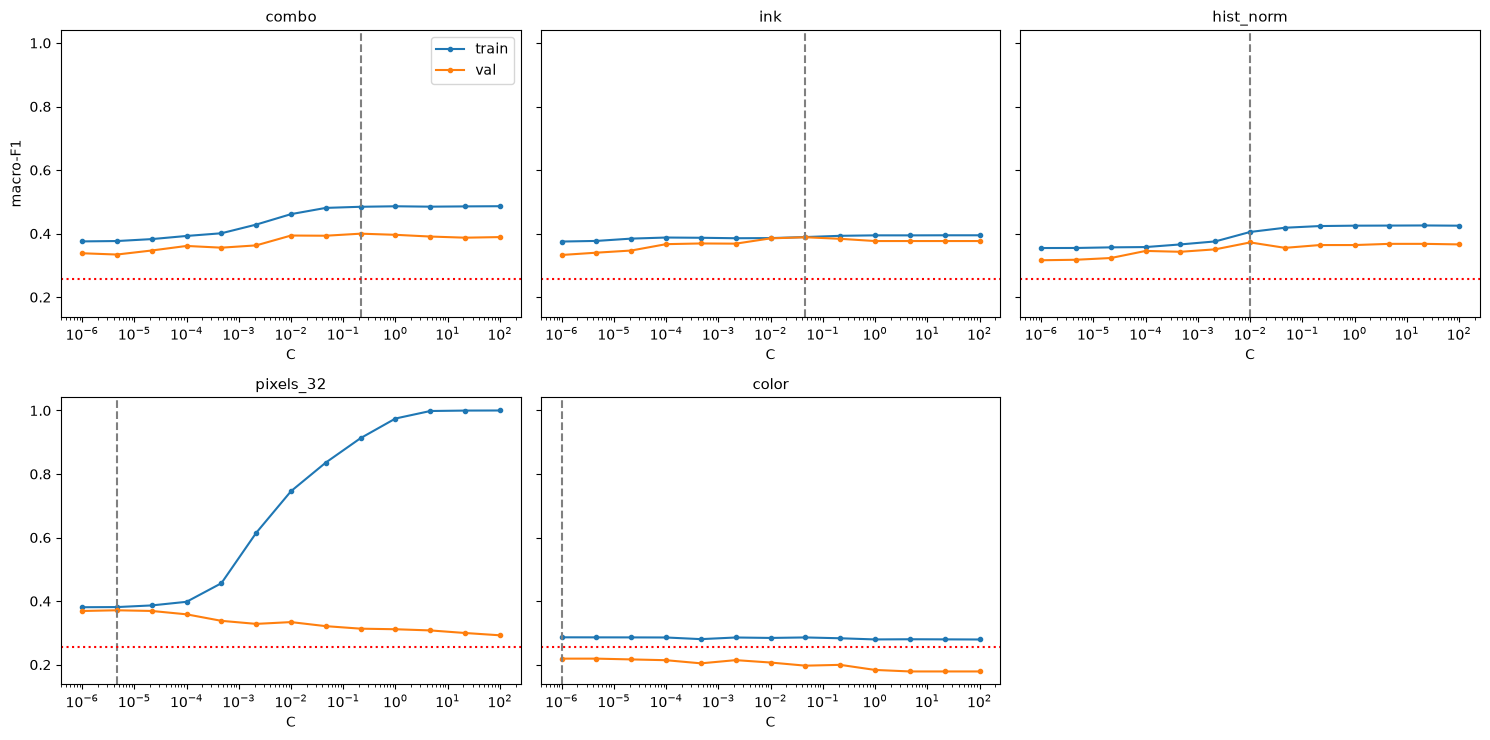

In [17]:
# Train vs. val curves across C. A big gap between the lines means overfitting. Two low, flat lines mean the feature doesn't carry much information.

plot_rows = feature_table.reset_index(drop=True)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
axes = axes.ravel()

for i in range(len(plot_rows)):
    name = plot_rows.loc[i, "feature"]
    feature_C = plot_rows.loc[i, "chosen_C"]

    # all the C values tried for this feature
    this_curve = curves[curves["feature"] == name]

    ax = axes[i]
    ax.plot(this_curve["C"], this_curve["train_macro_f1"], marker="o", markersize=3, label="train")
    ax.plot(this_curve["C"], this_curve["val_macro_f1"], marker="o", markersize=3, label="val")

    # gray dashed line = chosen C, red dotted line = chance level
    ax.axvline(feature_C, color="gray", linestyle="--")
    ax.axhline(chance_val_f1, color="red", linestyle=":")

    ax.set_xscale("log")
    ax.set_xlabel("C")
    ax.set_title(name, fontsize=11)

# 5 features but 6 spots: hide the empty one
for j in range(len(plot_rows), len(axes)):
    axes[j].axis("off")

axes[0].set_ylabel("macro-F1")
axes[0].legend()
plt.tight_layout()
plt.show()

## 7. Final model: combo

The combination model of hist_norm + ink + color side by side worked the best, with a Macro F1 score of ~0.40, which beats the chance model's macro F1 score of ~0.26. 

Chosen C: 2.15e-01
Val macro-F1 at that C: 0.400
Chance on val: 0.256


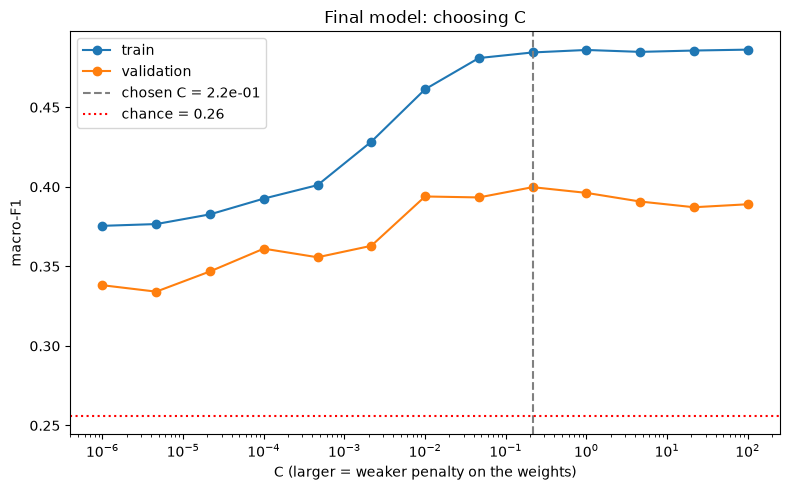

In [23]:
# Chosen in section 6 using the validation set: combo
FINAL_FEATURE = "combo"

# Src: DATASCI207
# Scale the features
# StandardScaler shifts and rescales every feature to mean 0 and standard deviation 1, so no feature counts more just because its numbers happen to be bigger.
# It learns the mean and std from the TRAINING data only. If it saw val or test, information about those maps would leak into training.
scaler = StandardScaler()
scaler.fit(X[FINAL_FEATURE]["train"])

# Apply that same training-based scaling to train, val and test
X_scaled = {}
for split_name in splits:
    X_scaled[split_name] = scaler.transform(X[FINAL_FEATURE][split_name])


# Look up combo's results from the section 6 search
# final_curve = combo's train and val scores at every C we tried (for the plot below)
final_curve = curves[curves["feature"] == FINAL_FEATURE]

# final_row: combo's one summary row.
final_row = feature_table[feature_table["feature"] == FINAL_FEATURE].iloc[0] # .iloc[0] takes the first (only) matching row.

chosen_C = final_row["chosen_C"] # the C picked for combo in section 6


#Print a quick summary
print(f"Chosen C: {chosen_C:.2e}")
print(f"Val macro-F1 at that C: {final_row['val_macro_f1']:.3f}")
print(f"Chance on val: {chance_val_f1:.3f}")

# Plot: how combo's train and val scores change with C
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(final_curve["C"], final_curve["train_macro_f1"], marker="o", label="train")
ax.plot(final_curve["C"], final_curve["val_macro_f1"], marker="o", label="validation")

# Gray dashed line = the C we chose. Red dotted line = what guessing would score.
ax.axvline(chosen_C, color="gray", linestyle="--", label=f"chosen C = {chosen_C:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label=f"chance = {chance_val_f1:.2f}")

# C goes from 0.000001 to 100, so a log scale spaces the values out evenly
ax.set_xscale("log")
ax.set_xlabel("C (larger = weaker penalty on the weights)")
ax.set_ylabel("macro-F1")
ax.set_title("Final model: choosing C")
ax.legend()

plt.tight_layout()
plt.show()

## 8. Test set (run once)

Refit with the chosen C on train, then score test. Don't go back and change anything above after seeing these numbers, or the test score stops being an honest estimate.

For the efficiency-vs-accuracy section:
- **Training cost** = computing features for every training image + fitting
- **Inference cost per image** = loading + features + predicting, for one image

In [24]:
#Build final model
# max_iter = the most optimization steps it may take before stopping.
final_model = LogisticRegression(C=chosen_C, max_iter=MAX_ITER, random_state=SEED) #using rnadom_state so I get the same results every time
 

# Train it & time the training
t = time.perf_counter() #src: https://stackoverflow.com/questions/66036844/time-time-or-time-perf-counter-which-is-faster?__cf_chl_tk=gGOPjeytMAfl4xANAJdo8XDI5bCN5qs32PLxCSzrZh8-1793660829-1.0.1.1-.1qi8znX5CApK7Su37a6oxXRRQnzljd58A1AJz4lZX8
final_model.fit(X_scaled["train"], y["train"])
fit_seconds = time.perf_counter() - t


# Predict the test set, and time it
t = time.perf_counter()
test_pred = final_model.predict(X_scaled["test"])
predict_seconds = time.perf_counter() - t


#Score the predictions
test_scores = get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, average=None) #gives one F1 per class instead of the average: [Small, Medium, Large]


#Costs, for the efficiency-vs-accuracy section
n_train = len(y["train"])
n_test = len(y["test"])

#Training cost = making features for every training image +fitting the model
train_cost_seconds = sec_per_image[FINAL_FEATURE] * n_train + fit_seconds

# Inference Cost for 1 new image = making its features +its share of the prediction time.
inference_ms = (sec_per_image[FINAL_FEATURE] + predict_seconds / n_test) * 1000 #multiply by 1000 to turn seconds into milliseconds.


# Compare test to chance and to val. If test is much lower than val, the model fit the val set by luck.
print(f"Test macro-F1:     {test_scores['macro_f1']:.3f}   (chance: {chance_test_f1:.3f})")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}")
print(f"Test accuracy:     {test_scores['accuracy']:.3f}")
print(f"Val macro-F1 was:  {final_row['val_macro_f1']:.3f}")
print()

print(f"Training cost:  {train_cost_seconds:.1f} s  (fitting alone: {fit_seconds:.2f} s)")
print(f"Inference cost: {inference_ms:.1f} ms per image")
print()

# Precision, recall and F1 for each class.
#   precision = of the maps it called Small, how many really were Small
#   recall    = of the real Small maps, how many it found
#   support   = how many test maps are in that class
print(classification_report(y["test"], test_pred, target_names=CLASS_NAMES, digits=3))

Test macro-F1:     0.331   (chance: 0.255)
Test balanced acc: 0.339
Test accuracy:     0.567
Val macro-F1 was:  0.400

Training cost:  84.3 s  (fitting alone: 0.07 s)
Inference cost: 27.4 ms per image

              precision    recall  f1-score   support

       Small      0.000     0.000     0.000        25
      Medium      0.233     0.321     0.270        53
       Large      0.751     0.695     0.722       213

    accuracy                          0.567       291
   macro avg      0.328     0.339     0.331       291
weighted avg      0.592     0.567     0.578       291



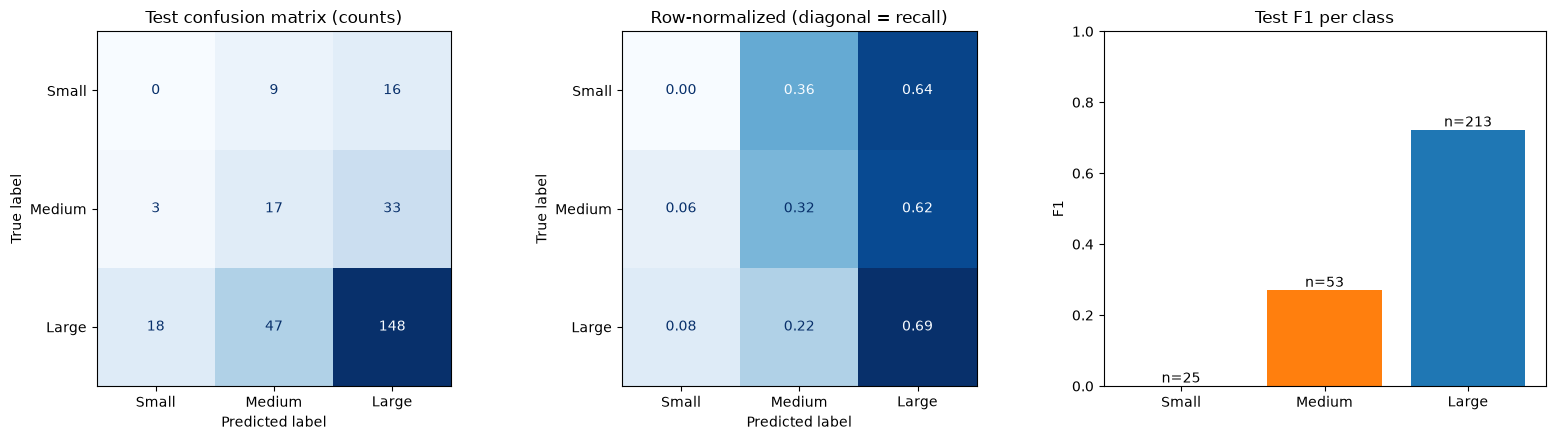

In [25]:
# Confusion Matrix, Src: DATASCI207

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


counts = confusion_matrix(y["test"], test_pred)
ConfusionMatrixDisplay(counts, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Test confusion matrix (counts)")

# Each row adds up to 1, so the diagonal is the recall of that class
rates = confusion_matrix(y["test"], test_pred, normalize="true")
ConfusionMatrixDisplay(rates, display_labels=CLASS_NAMES).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Row-normalized (diagonal = recall)")

class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=["tab:green", "tab:orange", "tab:blue"])
for k in range(3):
    bar = bars[k]
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("F1")
axes[2].set_title("Test F1 per class")

plt.tight_layout()
plt.show()